In [ ]:
%matplotlib widget 



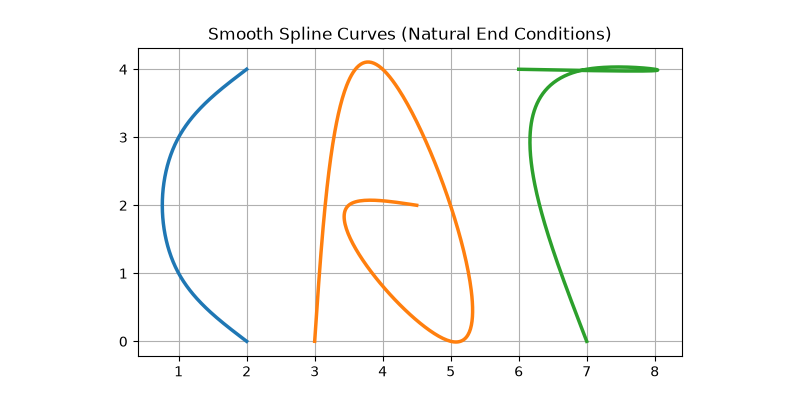

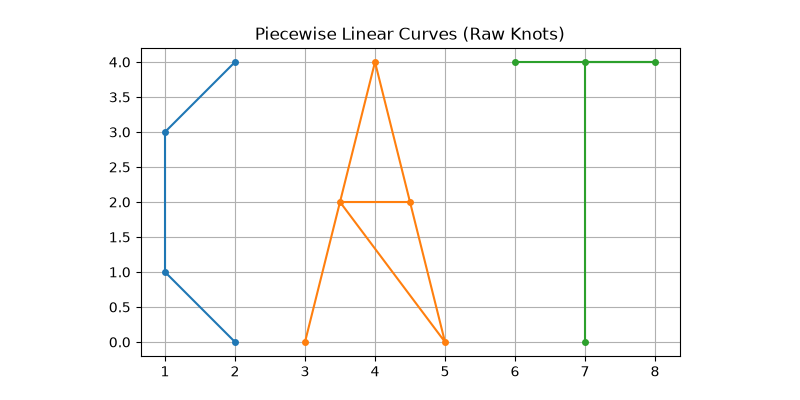

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline

def collect_curve_datasets():
    curves = []

    curve_idx = 1
    while True:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.set_title(f"Click points for Curve #{curve_idx} (Press Enter to finish curve)")
        ax.set_xlim(0, 10)
        ax.set_ylim(0, 5)
        ax.grid(True)
        
        pts = plt.ginput(n=-1, timeout=0)
        plt.close(fig)
        
        if len(pts) == 0:
            break
            
        curves.append(np.array(pts))
        curve_idx += 1
        
    return curves


def get_hardcoded_curves():
    c1 = np.array([[2, 4], [1, 3], [1, 1], [2, 0]])            # 'C'
    c2 = np.array([[3, 0], [4, 4], [5, 0], [3.5, 2], [4.5, 2]]) # 'A'
    c3 = np.array([[6, 4], [8, 4], [7, 4], [7, 0]])            # 'T'
    return [c1, c2, c3]


curves = get_hardcoded_curves() 
#curves = collect_curve_datasets()

fig1, ax1 = plt.subplots(figsize=(8, 4))
ax1.set_title("Piecewise Linear Curves (Raw Knots)")
ax1.grid(True)
ax1.set_aspect('equal')

fig2, ax2 = plt.subplots(figsize=(8, 4))
ax2.set_title("Smooth Spline Curves (Natural End Conditions)")
ax2.grid(True)
ax2.set_aspect('equal')

for curve in curves:
    x = curve[:, 0]
    y = curve[:, 1]
    
    ax1.plot(x, y, '-o', linewidth=1.5, markersize=4)
    
    distances = np.sqrt(np.diff(x)**2 + np.diff(y)**2)
    t = np.zeros(len(x))
    t[1:] = np.cumsum(distances)
    
    spl_x = make_interp_spline(t, x, k=3, bc_type='natural')
    spl_y = make_interp_spline(t, y, k=3, bc_type='natural')
    
    t_fine = np.linspace(t[0], t[-1], 300)
    x_fine = spl_x(t_fine)
    y_fine = spl_y(t_fine)
    
    ax2.plot(x_fine, y_fine, linewidth=2.5)

plt.show()